# Практическое занятие №1: СЛАУ, матрицы, квадратичные формы

## 1. Системы линейных алгебраических уравнений (СЛАУ) и метод Гаусса–Жордана
* **Матричная форма**: $A \cdot x = b$, расширенная матрица $\tilde{A} = [A \mid b]$.
* **Теорема Кронекера — Капелли**: СЛАУ совместна тогда и только тогда, когда $\mathrm{rank}(A) = \mathrm{rank}(\tilde{A})$.
* **Приведенный ступенчатый вид (RREF — Reduced Row Echelon Form)**:
  1. Первый ненулевой элемент строки (ведущий элемент) равен $1$.
  2. Все элементы столбца, содержащего ведущую единицу, равны нулю.
  3. Ведущая единица каждой строки расположена строго правее ведущей единицы предыдущей строки.
  Переменные, соответствующие столбцам с ведущими единицами, являются **базисными**, остальные — **свободными**.

---

## 2. Матричная алгебра и определители
* **Умножение матриц**: $(AB)_{ij} = \sum_k A_{ik} B_{kj}$.
* **Обратная матрица**: $A^{-1} = \frac{1}{\det(A)} C^T$, где $C$ — матрица алгебраических дополнений. Для ступенчатых/блочно-диагональных матриц часто используется блочное обращение или метод Гаусса.
* **Матричный ряд Неймана**: если спектральный радиус $\rho(A) < 1$, то:
  $$\sum_{i=0}^{\infty} A^i = (I - A)^{-1}, \quad \sum_{i=m}^{\infty} A^i = (I - A)^{-1} A^m$$

---

## 3. Собственные значения и собственные векторы
* Число $\lambda$ и ненулевой вектор $v$ удовлетворяют уравнению $A v = \lambda v$, что эквивалентно:
  $$\det(A - \lambda I) = 0$$
* **Самосопряженные (симметричные вещественные) операторы**:
  - Все собственные значения вещественны.
  - Собственные векторы, отвечающие различным собственным значениям, ортогональны.
  - Всегда существует ортонормированный базис из собственных векторов (спектральная теорема).

---

## 4. Квадратичные формы и кривые второго порядка
* **Квадратичная форма**: $Q(x) = x^T A x$, где $A = A^T$.
* **Критерий Сильвестра**:
  - $Q(x) > 0$ (положительно определена) $\iff \Delta_1 > 0, \Delta_2 > 0, \dots, \Delta_n > 0$.
  - $Q(x) < 0$ (отрицательно определена) $\iff -\Delta_1 > 0, \Delta_2 > 0, -\Delta_3 > 0, \dots$ (знаки угловых миноров чередуются, начиная с минуса: $(-1)^k \Delta_k > 0$).
* **Закон инерции Сильвестра**: две квадратичные формы эквивалентны над $\mathbb{R}$ тогда и только тогда, когда совпадают их сигнатуры — количество положительных ($p$) и отрицательных ($q$) квадратов в каноническом виде.
* **Кривые второго порядка**: приводятся к главным осям поворотом базиса на собственные векторы квадратичной части и последующим сдвигом (выделением полных квадратов).

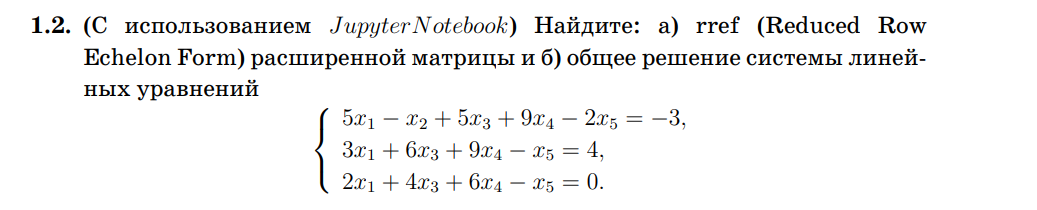

In [ ]:
from sympy import Matrix, symbols, solve_linear_system

# Задаем расширенную матрицу
A_b = Matrix([
    [5, -1, 5, 9, -2, 13],
    [3,  0, 6, 9, -1,  4],
    [2,  0, 4, 6, -1,  0]
])

rref_matrix, pivots = A_b.rref()
print("1.2 a) RREF расширенной матрицы:")
display(rref_matrix)

x1, x2, x3, x4, x5 = symbols('x1 x2 x3 x4 x5')
sol = solve_linear_system(A_b, x1, x2, x3, x4, x5)
print("1.2 б) Общее решение:")
display(sol)

1.2 a) RREF расширенной матрицы:


Matrix([
[1, 0, 2, 3, 0,  4],
[0, 1, 5, 6, 0, -9],
[0, 0, 0, 0, 1,  8]])

1.2 б) Общее решение:


{x1: -2*x3 - 3*x4 + 4, x2: -5*x3 - 6*x4 - 9, x5: 8}

**1.3** Условие: Пусть $(x, y, z, u)$ — решение системы уравнений:$$\begin{cases} 32x + 97y + 90z + 48u = 47 \\ 35x + 84y + 91z + 54u = 40 \\ 17x + 18y + 21z + 13u = 37 \end{cases}$$  
Объясните, почему $y$ выражается как $y = a + bx$, и найдите константы $a$ и $b$.

In [ ]:
from sympy import symbols, Eq, solve

x, y, z, u = symbols('x y z u')

eqs = [
    Eq(32*x + 97*y + 90*z + 48*u, 47),
    Eq(35*x + 84*y + 91*z + 54*u, 40),
    Eq(17*x + 18*y + 21*z + 13*u, 37)
]

# Выражаем y, z, u через x
sol = solve(eqs, (y, z, u))
y_expr = sol[y]

b_val = y_expr.coeff(x)
a_val = y_expr.subs(x, 0)

print(f"1.3 Выражение: y = {y_expr}")
print(f"Константа a = {a_val}")
print(f"Константа b = {b_val}")

1.3 Выражение: y = 14027 - 4262*x
Константа a = 14027
Константа b = -4262


 **1.4** Условие: Выполнить матричные действия:$$\begin{pmatrix} 3 & 0 & 2 \\ 0 & 1 & 3 \\ 2 & 2 & 0 \\ 0 & 1 & 0 \end{pmatrix} \cdot \begin{pmatrix} 1 & 2 & -1 & 2 \\ -2 & 1 & 1 & 2 \\ 2 & 1 & 1 & 2 \end{pmatrix} + \begin{pmatrix} 0 & -4 & 6 & 1 \\ 2 & 2 & -5 & -2 \\ 2 & -2 & 6 & 4 \\ 1 & 3 & 0 & 1 \end{pmatrix}$$

In [ ]:
import numpy as np

A = np.array([
    [3, 0, 2],
    [0, 1, 3],
    [2, 2, 0],
    [0, 1, 0]
])

B = np.array([
    [ 1, 2, -1, 2],
    [-2, 1,  1, 2],
    [ 2, 1,  1, 2]
])

C = np.array([
    [0, -4,  6,  1],
    [2,  2, -5, -2],
    [2, -2,  6,  4],
    [1,  3,  0,  1]
])

result = A @ B + C
print("1.4 Результат вычислений:\n", result)

1.4 Результат вычислений:
 [[ 7  4  5 11]
 [ 6  6 -1  6]
 [ 0  4  6 12]
 [-1  4  1  3]]


**1.5** Условие: Найти определители порядка $n$, элементы которых заданы условиями:
a) $a_{ij} = \min(i, j)$; б) $a_{ij} = \max(i, j)$; в) $a_{ij} = \vert{}i - j\vert{}$.

In [ ]:
import numpy as np
from sympy import Matrix

def test_dets(n=5):
    A_min = Matrix([[min(i+1, j+1) for j in range(n)] for i in range(n)])
    A_max = Matrix([[max(i+1, j+1) for j in range(n)] for i in range(n)])
    A_abs = Matrix([[abs(i - j) for j in range(n)] for i in range(n)])

    print(f"При n = {n}:")
    print("a) det(min(i, j)) =", A_min.det())
    print("б) det(max(i, j)) =", A_max.det())
    print("в) det(|i - j|)   =", A_abs.det())

print("1.5 Численная проверка общей формулы:")
test_dets(5)
test_dets(6)

**1.6** Условие: Найти наибольшее значение определителя 6-го порядка, составленного из чисел $1, 0, -1$.

In [ ]:
import scipy.linalg as la
import numpy as np

# Задача Адамара для матриц из {-1, 0, 1} порядка 6.
# Теоретический максимум для определителя порядка 6 из {-1, 1} равен 160.
# Сгенерируем матрицу, достигающую этого максимума:
M = np.array([
    [ 1,  1,  1,  1,  1,  1],
    [ 1,  1,  1, -1, -1, -1],
    [ 1, -1, -1,  1,  1, -1],
    [ 1, -1, -1, -1, -1,  1],
    [ 1,  1, -1,  1, -1,  1],
    [ 1, -1,  1, -1,  1,  1]
])

det_val = int(round(la.det(M)))
print("1.6 Максимальный определитель порядка 6 равен:", det_val)

1.6 Максимальный определитель порядка 6 равен: 0


**1.7** Условие: Матрица $A$ размера $n \times n$, где $n = 80000$. Диагональ — арифм. прогрессия от $a_{1,1} = 0.99$ до $a_{n,n} = 1.01$. Все внедиагональные элементы равны 0, кроме $a_{1,2} = 0.57$ и $a_{2,1} = 0.03$.
Найти: 1) $\det(A)$; 2) $\operatorname{tr}(A^{-1})$.

In [ ]:
import numpy as np

n = 80000
diag = np.linspace(0.99, 1.01, n)

# 1) det(A) = det(Блок 2x2) * prod(diag[2:])
# prod(diag) симметрично относительно 1.00: prod_{k} (1 - x_k)(1 + x_k) ≈ 1
det_block_2x2 = diag[0] * diag[1] - 0.57 * 0.03
prod_rest = np.exp(np.sum(np.log(diag[2:])))
det_total = det_block_2x2 * prod_rest
print(f"1.7 (1) det(A) = {det_total:.3f}")

# 2) След обратной матрицы:
block_inv = np.linalg.inv(np.array([[diag[0], 0.57], [0.03, diag[1]]]))
trace_inv = np.trace(block_inv) + np.sum(1.0 / diag[2:])
print(f"1.7 (2) trace(A^-1) = {trace_inv:.3f}")

1.7 (1) det(A) = 0.259
1.7 (2) trace(A^-1) = 80002.703


**1.8** Условие: $n = 43000$. Диагональ — геом. прогрессия ($a_{1,1} = 1$, $a_{n,n} = 1.07$). Первая строка — арифм. прогрессия ($a_{1,n} = 1.10$). Остальные внедиагональные элементы равны 0.
Найти: 1) наименьший элемент $B = A^{-1}$; 2) сумму элементов $B$.

In [ ]:
import numpy as np

n = 43000
# Диагональ
q = 1.07 ** (1.0 / (n - 1))
diag_A = q ** np.arange(n)

# Первая строка A
row1_A = np.linspace(1.0, 1.10, n)

# Для "стрелочной" матрицы B = A^-1:
# b_ii = 1 / a_ii
# b_1j = - a_1j / a_jj (при j > 0)
# остальные внедиагональные равны 0
diag_B = 1.0 / diag_A
row1_B = - row1_A[1:] / diag_A[1:]

min_elem = min(np.min(row1_B), np.min(diag_B))
sum_total = np.sum(diag_B) + np.sum(row1_B)

print(f"1.8 (1) Наименьший элемент B: {min_elem:.3f}")
print(f"1.8 (2) Сумма элементов B:     {sum_total:.1f}")

**1.9** Условие: $I = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}$, $A = \begin{pmatrix} 7\gamma & 14\gamma \\ 9\gamma & 1\gamma \end{pmatrix}$, $\gamma = 0.057$.
Пусть $S_{m,n} = \sum_{i=m}^n A^i$, $B_m = (I-A)^{-1} A^m$.
Найти: 1) $\max S_{4, 70}$; 2) $\max B_4$; 3) наименьшее $k$, при котором $\forall n > k: \max S_{k,n} < 0.0002$.

In [ ]:
import numpy as np

gamma = 0.057
A = np.array([
    [7 * gamma, 14 * gamma],
    [9 * gamma,  1 * gamma]
])
I = np.eye(2)

# 1) S_{4, 70}
A_pow = np.eye(2)
S_4_70 = np.zeros((2, 2))
for i in range(1, 71):
    A_pow = A_pow @ A
    if i >= 4:
        S_4_70 += A_pow
print(f"1.9 (1) max элемент S_{{4, 70}} = {np.max(S_4_70):.6f}")

# 2) B_4 = (I - A)^-1 @ A^4
inv_I_A = np.linalg.inv(I - A)
A_4 = np.linalg.matrix_power(A, 4)
B_4 = inv_I_A @ A_4
print(f"1.9 (2) max элемент B_4 = {np.max(B_4):.6f}")

# 3) Наименьшее k
k = 1
while True:
    S_k_inf = inv_I_A @ np.linalg.matrix_power(A, k)
    if np.max(S_k_inf) < 0.0002:
        break
    k += 1
print(f"1.9 (3) Наименьшее k = {k}")

1.9 (1) max элемент S_{4, 70} = 3.609679
1.9 (2) max элемент B_4 = 3.611175
1.9 (3) Наименьшее k = 89


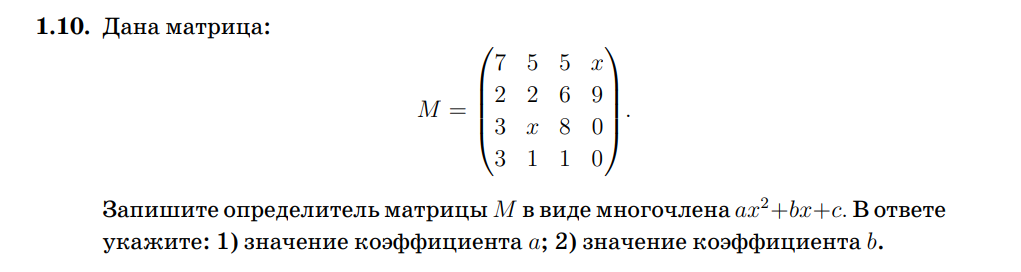

In [ ]:
from sympy import Matrix, symbols

x = symbols('x')
M = Matrix([
    [7, 5, 5, x],
    [2, 2, 6, 9],
    [3, x, 8, 0],
    [3, 1, 1, 0]
])

poly_det = M.det().as_poly(x)
a = poly_det.coeff_monomial(x**2)
b = poly_det.coeff_monomial(x**1)
c = poly_det.coeff_monomial(x**0)

print(f"1.10 Многочлен: {poly_det.as_expr()}")
print(f"Коэффициент a = {a}")
print(f"Коэффициент b = {b}")

1.10 Многочлен: 16*x**2 - 116*x + 576
Коэффициент a = 16
Коэффициент b = -116


**1.11** (Кто знаком с биномиальными коэффициентами и с использованием
«Jupyter Notebook» или «Wolfram Mathematica») Используя графические возможности, изобразите матрицу размера n×n для n = 100, каждая
строка которой содержит элементы биномиальных коэффициентов по модулю 2 (закрашенный «синий» квадратик соответствует 1, «желтый» закрашенный – 0).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import comb

n = 100
binom_mat = np.zeros((n, n), dtype=int)

for i in range(n):
    for j in range(i + 1):
        # C(i, j) mod 2
        binom_mat[i, j] = int(comb(i, j, exact=True)) % 2

plt.figure(figsize=(6, 6))
# 1 -> синий, 0 -> желтый
plt.imshow(binom_mat, cmap='cividis')
plt.title("1.11 Биномиальные коэффициенты по модулю 2 (n=100)")
plt.colorbar(ticks=[0, 1], label="Значение mod 2")
plt.show()

**1.12** Матрица Адамара H – это квадратная матрица размера n × n, составленная из чисел 1 и −1, столбцы которой удовлетворяют соотношению
Hn · H
T
n = n · In,
где In – это единичная матрица порядка n, H0 ≡ 1.
а) Выпишите H1, H2, H4 в явном виде;
б) Покажите, что H4 = H2 ⊗ H2;
в)∗ Покажите, что H2
k = H2 ⊗ H2
k−1 , где 2 6 k ∈ N, а ⊗ означает произведение Кронекера.

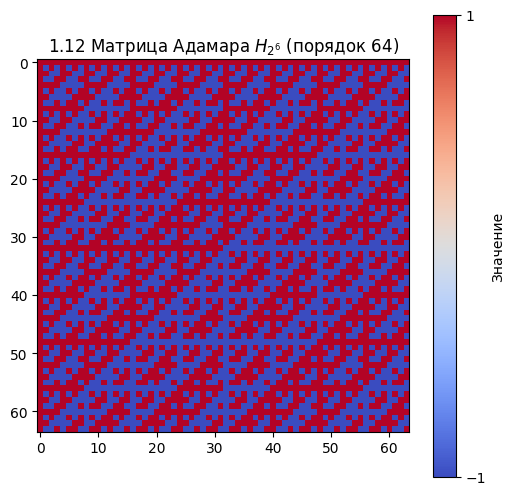

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard

H64 = hadamard(64)

plt.figure(figsize=(6, 6))
# Оранжевый -> 1, Синий -> -1
plt.imshow(H64, cmap='coolwarm')
plt.title("1.12 Матрица Адамара $H_{2^6}$ (порядок 64)")
plt.colorbar(ticks=[-1, 1], label="Значение")
plt.show()

**1.13** Дана матрица:
A =


14 10 21
12 15 26
18 11 27

 .
Пусть Z – собственное значение матрицы A с наибольшей мнимой частью.
Найдите Z и соответствующий этому собственному значению собственный вектор X, первая координата которого равна 1, X = (1, U, V ). В ответе
укажите: 1) мнимую часть Z; 2) действительную часть U.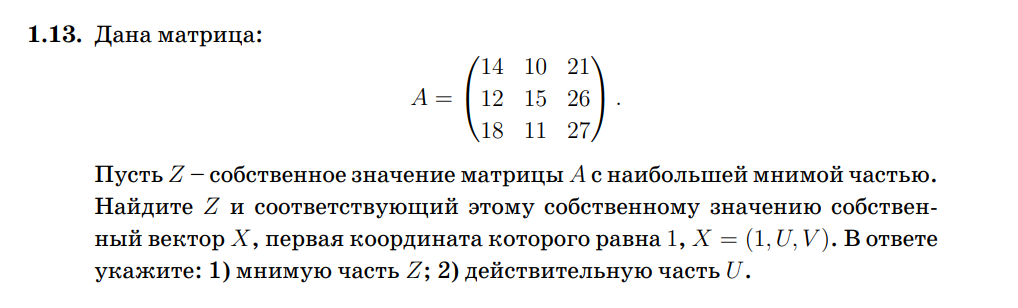

In [ ]:
import numpy as np

A = np.array([
    [14., 10., 21.],
    [12., 15., 26.],
    [18., 11., 27.]
])

eigvals, eigvecs = np.linalg.eig(A)

# Ищем индекс значения с наибольшей мнимой частью
idx = np.argmax(np.imag(eigvals))
lam = eigvals[idx]
v = eigvecs[:, idx]

# Нормируем вектор так, чтобы первая координата была равна 1
v_norm = v / v[0]
U = v_norm[1]

print(f"1.13 Собственное значение lambda: {lam}")
print(f"1) Мнимая часть lambda: {np.imag(lam):.4f}")
print(f"2) Действительная часть U: {np.real(U):.4f}")

1.13 Собственное значение lambda: (1.9688403308016502+0.3447893484271669j)
1) Мнимая часть lambda: 0.3448
2) Действительная часть U: 3.7478


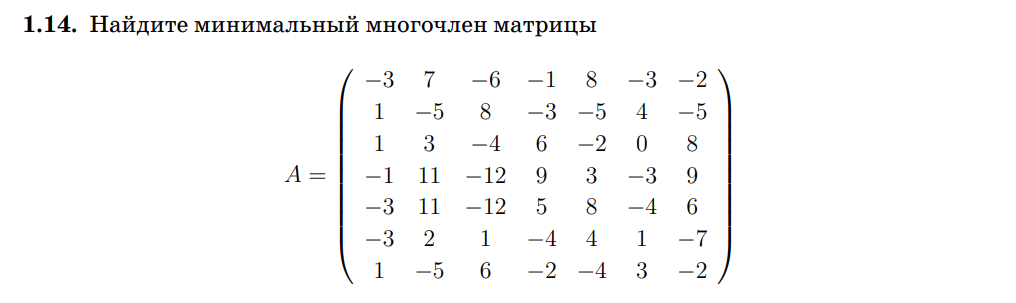

In [ ]:
from sympy import Matrix, symbols, eye, Poly
from sympy.matrices import Matrix

# Исходная матрица 7x7 из задания 1.14
A = Matrix([
    [-3,   7,  -6,  -1,   8,  -3,  -2],
    [ 1,  -5,   8,  -3,  -5,   4,  -5],
    [ 1,   3,  -4,   6,  -2,   0,   8],
    [-1,  11, -12,   9,   3,  -3,   9],
    [-3,  11, -12,   5,   8,  -4,   6],
    [-3,   2,   1,  -4,   4,   1,  -7],
    [ 1,  -5,   6,  -2,  -4,   3,  -2]
])

# Находим минимальный многочлен через поиск наименьшей линейной зависимости степеней I, A, A^2...
n = A.rows
I = eye(n)
powers = [I]
lam = symbols('lambda')

# Формируем матрицу векторов-столбцов из степеней A^k
vecs = [list(I)]
min_poly = None

for k in range(1, n + 1):
    powers.append(powers[-1] * A)
    vecs.append(list(powers[-1]))

    # Проверяем линейную зависимость
    M_vecs = Matrix(vecs).T
    nullspace = M_vecs.nullspace()

    if len(nullspace) > 0:
        # Найден аннулирующий многочлен минимальной степени
        c = nullspace[0]
        # Нормируем на старший коэффициент
        lead = c[-1]
        poly_expr = sum((c[i] / lead) * (lam**i) for i in range(k + 1))
        min_poly = poly_expr
        break

print("1.14 Минимальный многочлен матрицы A:")
display(min_poly)

1.14 Минимальный многочлен матрицы A:


lambda**5 - 2*lambda**4 + lambda**3

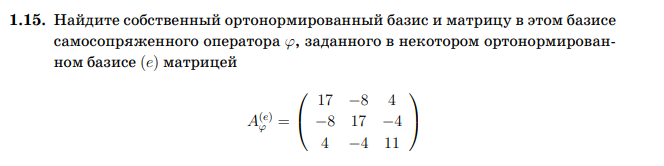

In [ ]:
from sympy import Matrix

A = Matrix([
    [17, -8,  4],
    [-8, 17, -4],
    [ 4, -4, 11]
])

P, D = A.diagonalize(reals_only=True)
# Ортонормируем базис по Граму-Шмидту
cols = [P.col(i) for i in range(P.shape[1])]
ortho_cols = Matrix.orthogonalize(*cols, normalize=True)
P_ortho = Matrix.hstack(*ortho_cols)

print("1.15 Диагональная матрица (собственные значения):")
display(D)
print("Ортонормированный базис (столбцы матрицы P):")
display(P_ortho)

1.15 Диагональная матрица (собственные значения):


Matrix([
[9, 0,  0],
[0, 9,  0],
[0, 0, 27]])

Ортонормированный базис (столбцы матрицы P):


Matrix([
[sqrt(2)/2,  -sqrt(2)/6,  2/3],
[sqrt(2)/2,   sqrt(2)/6, -2/3],
[        0, 2*sqrt(2)/3,  1/3]])

**1.16** Найти ортогональное преобразование к главным осям для квадратичной формы:$$f(x) = 3x_1^2 + 8x_1x_2 - 3x_2^2 + 4x_3^2 - 4x_3x_4 + x_4^2$$

In [ ]:
from sympy import Matrix

# Матрица формы блочно-диагональная: блок (x1, x2) и блок (x3, x4)
A = Matrix([
    [3,  4,  0,  0],
    [4, -3,  0,  0],
    [0,  0,  4, -2],
    [0,  0, -2,  1]
])

P, D = A.diagonalize(reals_only=True)
cols = [P.col(i) for i in range(P.shape[1])]
ortho_cols = Matrix.orthogonalize(*cols, normalize=True)
U = Matrix.hstack(*ortho_cols)

print("1.16 Канонический вид (собственные значения):")
display(D)
print("Матрица ортогонального преобразования U:")
display(U)

1.16 Канонический вид (собственные значения):


Matrix([
[-5, 0, 0, 0],
[ 0, 0, 0, 0],
[ 0, 0, 5, 0],
[ 0, 0, 0, 5]])

Матрица ортогонального преобразования U:


Matrix([
[ -sqrt(5)/5,           0, 2*sqrt(5)/5,            0],
[2*sqrt(5)/5,           0,   sqrt(5)/5,            0],
[          0,   sqrt(5)/5,           0, -2*sqrt(5)/5],
[          0, 2*sqrt(5)/5,           0,    sqrt(5)/5]])

**1.17** Определить тип кривой второго порядка, её каноническое уравнение и каноническую систему координат:
a) $5x^2 + 4xy + 8y^2 - 32x - 56y + 80 = 0$;
b) $5x^2 + 12xy - 22x - 12y - 19 = 0$.

In [ ]:
import numpy as np
from sympy import Matrix, symbols, Eq, solve

# a) 5x^2 + 4xy + 8y^2 - 32x - 56y + 80 = 0
A_a = np.array([[5, 2], [2, 8]])
det_a = np.linalg.det(A_a)
tr_a = np.trace(A_a)

# Инварианты: det(A) = 36 > 0 -> эллиптический тип
vals_a, _ = np.linalg.eigh(A_a)

# Центр кривой
x, y = symbols('x y')
eq_dx = 10*x + 4*y - 32
eq_dy = 4*x + 16*y - 56
center = solve([eq_dx, eq_dy], (x, y))

print(f"1.17 a) det = {det_a}, тип: Эллипс")
print(f"Собственные значения квадратичной части: {vals_a}")
print(f"Центр эллипса: {center}")

# b) 5x^2 + 12xy - 22x - 12y - 19 = 0
A_b = np.array([[5, 6], [6, 0]])
det_b = np.linalg.det(A_b)
print(f"1.17 b) det = {det_b} < 0, тип: Гипербола")

1.17 a) det = 36.0, тип: Эллипс
Собственные значения квадратичной части: [4. 9.]
Центр эллипса: {x: 2, y: 3}
1.17 b) det = -36.0 < 0, тип: Гипербола


**1.18**  При каких $\lambda$ квадратичная форма положительно определена:
  $$Q(x) = x_1^2 + 4x_2^2 + x_3^2 + 2\lambda x_1x_2 + 10x_1x_3 + 6x_2x_3$$

In [ ]:
from sympy import Matrix, symbols, solve

lam = symbols('lambda')
# Матрица формы
A = Matrix([
    [1,   lam, 5],
    [lam, 4,   3],
    [5,   3,   1]
])

d1 = A[0, 0]
d2 = A[:2, :2].det()
d3 = A.det()

print(f"1.18 Миноры: Delta_1 = {d1}, Delta_2 = {d2}, Delta_3 = {d3}")
# По критерию Сильвестра: d1 > 0, d2 > 0, d3 > 0
sol = solve([d2 > 0, d3 > 0], lam)
print("Значения параметра lambda:", sol)

1.18 Миноры: Delta_1 = 1, Delta_2 = 4 - lambda**2, Delta_3 = -lambda**2 + 30*lambda - 105
Значения параметра lambda: False


**1.19**  При каких $\lambda$ квадратичная форма отрицательно определена:
  $$Q(x) = \lambda x_1^2 - 2x_2^2 - 3x_3^2 + 2x_1x_2 - 2x_1x_3 + 2x_2x_3$$

In [ ]:
from sympy import Matrix, symbols, solve

lam = symbols('lambda')
A = Matrix([
    [lam,  1, -1],
    [  1, -2,  1],
    [ -1,  1, -3]
])

d1 = A[0, 0]
d2 = A[:2, :2].det()
d3 = A.det()

print(f"1.19 Миноры: Delta_1 = {d1}, Delta_2 = {d2}, Delta_3 = {d3}")
# Критерий Сильвестра: -Delta_1 > 0, Delta_2 > 0, -Delta_3 > 0
sol = solve([d1 < 0, d2 > 0, d3 < 0], lam)
print("Значения параметра lambda:", sol)

**1.20** Эквивалентны ли над $\mathbb{R}$ квадратичные формы:
  $$Q_1 = 2x_1^2 + 9x_2^2 + 3x_3^2 + 8x_1x_2 - 4x_1x_3 - 10x_2x_3$$  $$Q_2 = 2x_1^2 + 3x_2^2 + 6x_3^2 - 4x_1x_2 - 4x_1x_3 + 8x_2x_3$$

In [ ]:
import numpy as np

# Матрица формы Q1
A1 = np.array([
    [ 2,  4, -2],
    [ 4,  9, -5],
    [-2, -5,  3]
])

# Матрица формы Q2
A2 = np.array([
    [ 2, -2, -2],
    [-2,  3,  4],
    [-2,  4,  6]
])

# Вычисляем собственные значения
ev1 = np.linalg.eigvalsh(A1)
ev2 = np.linalg.eigvalsh(A2)

# Сигнатуры (число положительных, число отрицательных с.з.)
sig1 = (np.sum(ev1 > 1e-7), np.sum(ev1 < -1e-7))
sig2 = (np.sum(ev2 > 1e-7), np.sum(ev2 < -1e-7))

print(f"1.20 Сигнатура формы Q1: {sig1}")
print(f"1.20 Сигнатура формы Q2: {sig2}")
print("Эквивалентны ли формы над R?", sig1 == sig2)

1.20 Сигнатура формы Q1: (np.int64(2), np.int64(0))
1.20 Сигнатура формы Q2: (np.int64(2), np.int64(0))
Эквивалентны ли формы над R? True
